# LSTM forecasting models — training and out-of-sample statistics

This notebook trains four LSTM forecasters, one per feature set, under exactly
the protocol used for the iTransformer results reported in the manuscript:

| | |
|---|---|
| Feature sets | `price+volume`, `+sentiment`, `+technicals`, `full` — built from the same raw files |
| Lookback | 168 hours (7 days), target = next-hour change of the BTCUSDT close, in USD |
| Date window | one window common to all four sets, so row-wise deletion cannot shift the split |
| Split | training ends **2024-04-30**, May 2024 is a buffer month |
| Test regimes | uptrend Jun 2024 – Jan 2025, sideways Jan 2025 – (end of sentiment coverage) |
| Scaling | inputs and target standardised on training-period statistics |
| Epoch selection | on a 120-day inner-validation slice at the end of the training period |
| Seeds | 3 per feature set; tables report mean ± sd |
| Benchmarks | zero-change, training historical mean, random walk, AR(1), AR(24) |
| Tests | Diebold–Mariano on absolute errors, Newey–West variance, HLN correction, BH across the family |

Only the forecaster differs from the iTransformer study: a stacked LSTM encoder
with a linear head on the final hidden state, with its hyperparameters chosen by
an Optuna study per feature set.

Everything is written to `out/`; the trained models go to `checkpoints/` and are
consumed by `02_lstm_backtesting.ipynb`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import optuna

import lstm_common as L

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ------------------------------------------------------------------ toggles
SEEDS = [0, 1, 2]
N_TRIALS = 50            # Optuna trials per feature set, as for the iTransformer
TUNE_EPOCHS = 5          # epochs per trial, on a reduced corpus (see below)
TUNE_CORPUS = 10_000     # first N training sequences per trial
TUNE_CORPUS_SMALL = 5_000        # for the price+volume set
SELECT_EPOCHS = 40       # max epochs for the epoch-selection run
SELECT_PATIENCE = 8
RUN_TUNING = True        # False -> reuse out/lstm_hparams.json

RESULTS = {}             # every table worth reporting lands here

print("device        :", L.DEVICE)
print("lookback      :", L.SEQ, "hours")
print("train ends    :", L.TRAIN_END.date(), " (inner validation from",
      L.INNER_VAL_START.date(), ")")
print("uptrend       :", L.UPTREND[0].date(), "->", L.UPTREND[1].date())
print("sideways      :", L.SIDEWAYS[0].date(), "->", L.SIDEWAYS[1].date())
print("output dir    :", L.OUT)

/home/kosmo/Documents/Magis-submit/src-vibe (Copy)/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device        : cuda
lookback      : 168 hours
train ends    : 2024-04-30  (inner validation from 2024-01-01 )
uptrend       : 2024-06-01 -> 2025-01-01
sideways      : 2025-01-01 -> 2025-06-01
output dir    : /home/kosmo/Documents/Magis-submit/src-vibe (Copy)/lstm_models/out


## 1. Data

The four feature sets are rebuilt from the raw 1-minute BTCUSDT file, the
FinBERT per-headline sentiment predictions and the technical series, with the
same resampling and aggregation rules as the iTransformer notebooks. They are
then restricted to the window all four have in common.

In [2]:
HOURLY = L.build_feature_sets()
lo, hi = L.common_window(HOURLY)
print(f"\ncommon window: {lo} -> {hi}")

HOURLY_C = L.restrict_to_common(HOURLY)
SIDEWAYS_END = min(L.SIDEWAYS[1], hi)
if SIDEWAYS_END < L.SIDEWAYS[1]:
    print(f"NOTE: sentiment coverage ends {hi.date()}, so the sideways window is "
          f"truncated to {L.SIDEWAYS[0].date()}..{SIDEWAYS_END.date()} for every "
          f"feature set, keeping the rows comparable.")

rows = []
for name in L.FEATURE_SET_ORDER:
    h = HOURLY_C[name]
    idx = h.index[L.SEQ:]
    rows.append(dict(
        feature_set=name, variates=h.shape[1], rows=len(h),
        fit=int((h.index < L.INNER_VAL_START).sum()),
        inner_val=int(((h.index >= L.INNER_VAL_START) & (h.index < L.TRAIN_END)).sum()),
        uptrend=int(L.regime_mask(idx, "Uptrend").sum()),
        sideways=int(L.regime_mask(idx, "Sideways", SIDEWAYS_END).sum()),
        columns=", ".join(h.columns)))
split_tbl = pd.DataFrame(rows)
RESULTS["data_split"] = split_tbl
print()
print(split_tbl.drop(columns="columns").to_string(index=False))
for r in rows:
    print(f"\n{r['feature_set']:26s} {r['columns']}")

price+volume               variates= 4  rows=71,857  (cache)
price+volume+sentiment     variates= 5  rows=54,633  (cache)
price+volume+technicals    variates=10  rows=52,339  (cache)
full                       variates=11  rows=48,024  (cache)

common window: 2019-09-30 14:00:00+00:00 -> 2025-03-31 14:00:00+00:00
NOTE: sentiment coverage ends 2025-03-31, so the sideways window is truncated to 2025-01-01..2025-03-31 for every feature set, keeping the rows comparable.

            feature_set  variates  rows   fit  inner_val  uptrend  sideways
           price+volume         4 48182 37247       2880     5136      2150
 price+volume+sentiment         5 48173 37238       2880     5136      2150
price+volume+technicals        10 48024 37115       2875     5120      2147
                   full        11 48024 37115       2875     5120      2147

price+volume               price_change_1h, close, usd_volume_buy, usd_volume_sell

price+volume+sentiment     price_change_1h, close, usd_volume_b

## 2. Hyperparameter search

One Optuna study per feature set, on the same budget the iTransformer study
used: 50 trials, each training for 5 epochs on a reduced corpus of the first
10,000 training sequences (5,000 for the price-and-volume set) to keep tuning
affordable. The search space covers the LSTM's capacity (hidden size, depth),
its regularisation (dropout) and the learning rate; a median pruner stops
unpromising trials early.

Two differences from the iTransformer search are worth stating. Trials are
scored on the **inner-validation slice**, not on the final-year window, so —
unlike the iTransformer selection, which the manuscript flags as not fully
independent of its own evaluation period — the test regimes are never touched
during selection. And the encoder is kept unidirectional: a bidirectional pass
over the lookback window is legitimate here (the whole window is past data),
but it costs one to two orders of magnitude more compute for a task where every
configuration converges to the same error level, so it is not searched.

In [3]:
HP_PATH = L.OUT / "lstm_hparams.json"

fit_mask = lambda idx: idx < L.INNER_VAL_START
inner_mask = lambda idx: (idx >= L.INNER_VAL_START) & (idx < L.TRAIN_END)
train_mask = lambda idx: idx < L.TRAIN_END


def tune(name, dfh, n_trials=N_TRIALS):
    corpus = TUNE_CORPUS_SMALL if name == "price+volume" else TUNE_CORPUS

    def objective(trial):
        hp = dict(
            hidden_size=trial.suggest_categorical("hidden_size", [32, 64, 128]),
            num_layers=trial.suggest_int("num_layers", 1, 2),
            dropout=trial.suggest_float("dropout", 0.0, 0.3),
            bidirectional=False,
            lr=trial.suggest_float("lr", 1e-5, 1e-2, log=True),
            batch_size=256,
        )
        run = L.train_eval(dfh, fit_mask, inner_mask, hp=hp, epochs=TUNE_EPOCHS,
                           seed=0, track=True, trial=trial, max_train=corpus)
        return run["best_mae"]

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=0),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials)
    hp = dict(study.best_params, bidirectional=False, batch_size=256)
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"{name:26s} corpus={corpus:,}  best inner-val MAE={study.best_value:8.2f}  "
          f"({time.time() - t0:5.0f}s, {len(study.trials)} trials, {n_pruned} pruned)  {hp}")
    return hp, study


if RUN_TUNING:
    BEST_HP, STUDIES = {}, {}
    for name in L.FEATURE_SET_ORDER:
        BEST_HP[name], STUDIES[name] = tune(name, HOURLY_C[name])
    HP_PATH.write_text(json.dumps(BEST_HP, indent=2))
else:
    BEST_HP = json.loads(HP_PATH.read_text())
    STUDIES = {}
    print("reusing", HP_PATH)

hp_tbl = pd.DataFrame([dict(feature_set=n, **BEST_HP[n]) for n in L.FEATURE_SET_ORDER])
RESULTS["lstm_hparams"] = hp_tbl
print()
print(hp_tbl.to_string(index=False))

price+volume               corpus=5,000  best inner-val MAE=  230.15  (   26s, 50 trials, 15 pruned)  {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.22369547825066707, 'lr': 0.0026237354160482443, 'bidirectional': False, 'batch_size': 256}


price+volume+sentiment     corpus=10,000  best inner-val MAE=  229.38  (   50s, 50 trials, 28 pruned)  {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.10305061156239637, 'lr': 0.002070425617055702, 'bidirectional': False, 'batch_size': 256}


price+volume+technicals    corpus=10,000  best inner-val MAE=  229.53  (   93s, 50 trials, 21 pruned)  {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.08858161779924152, 'lr': 0.001318093646586037, 'bidirectional': False, 'batch_size': 256}


full                       corpus=10,000  best inner-val MAE=  229.33  (  105s, 50 trials, 25 pruned)  {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.0030274803482685103, 'lr': 0.000921715929840511, 'bidirectional': False, 'batch_size': 256}

            feature_set  hidden_size  num_layers  dropout       lr  bidirectional  batch_size
           price+volume           32           1 0.223695 0.002624          False         256
 price+volume+sentiment           64           1 0.103051 0.002070          False         256
price+volume+technicals          128           1 0.088582 0.001318          False         256
                   full          128           1 0.003027 0.000922          False         256


## 3. Training under the corrected protocol

For each feature set and seed:

1. fit on data before the inner-validation slice and pick the epoch that
   minimises inner-validation MAE;
2. refit from scratch on the **whole** training period for that number of
   epochs;
3. predict both test regimes in one pass.

The refit models are kept — the three seeds of a feature set form the ensemble
whose averaged forecast drives the backtests in notebook 02.

In [4]:
runs, sel_runs = {}, {}
t_all = time.time()
for name in L.FEATURE_SET_ORDER:
    dfh = HOURLY_C[name]
    states = []
    for seed in SEEDS:
        t0 = time.time()
        sel = L.train_eval(dfh, fit_mask, inner_mask, hp=BEST_HP[name],
                           epochs=SELECT_EPOCHS, seed=seed, track=True,
                           patience=SELECT_PATIENCE)
        n_ep = max(1, sel["best_epoch"] + 1)
        run = L.train_eval(
            dfh, train_mask,
            lambda idx: (idx >= L.UPTREND[0]) & (idx < SIDEWAYS_END),
            hp=BEST_HP[name], epochs=n_ep, seed=seed, return_model=True)
        runs[(name, seed)] = run
        sel_runs[(name, seed)] = sel
        states.append(run["state_dict"])
        print(f"{name:26s} seed={seed}  epochs={n_ep:2d}  "
              f"inner-val MAE={sel['best_mae']:7.2f}  "
              f"test MAE={np.abs(run['pred'] - run['y']).mean():7.2f}  "
              f"({time.time() - t0:4.0f}s)")

    predictor = L.LSTMPredictor(states, runs[(name, SEEDS[0])]["scaler"],
                                BEST_HP[name], list(dfh.columns), dfh.shape[1])
    predictor.save(L.CKPT_DIR / f"lstm_{L.FOLDER_NAME[name]}.pt")

print(f"\ntotal training time: {(time.time() - t_all) / 60:.1f} min")
np.savez_compressed(
    L.OUT / "lstm_predictions.npz",
    **{f"{L.FOLDER_NAME[n]}__{s}__{k}": np.asarray(runs[(n, s)][k])
       for n in L.FEATURE_SET_ORDER for s in SEEDS
       for k in ("pred", "y", "close_prev", "close")},
    **{f"{L.FOLDER_NAME[n]}__{s}__idx": runs[(n, s)]["idx"].astype(str).to_numpy()
       for n in L.FEATURE_SET_ORDER for s in SEEDS})
print("predictions saved to", L.OUT / "lstm_predictions.npz")

price+volume               seed=0  epochs= 5  inner-val MAE= 229.10  test MAE= 285.64  (   5s)


price+volume               seed=1  epochs= 2  inner-val MAE= 229.25  test MAE= 285.92  (   4s)


price+volume               seed=2  epochs= 3  inner-val MAE= 229.30  test MAE= 285.36  (   4s)


price+volume+sentiment     seed=0  epochs= 6  inner-val MAE= 229.23  test MAE= 286.06  (   9s)


price+volume+sentiment     seed=1  epochs= 4  inner-val MAE= 229.35  test MAE= 285.45  (   7s)


price+volume+sentiment     seed=2  epochs= 5  inner-val MAE= 229.42  test MAE= 285.67  (   8s)


... (3 outputs left out)

full                       seed=0  epochs= 2  inner-val MAE= 229.39  test MAE= 285.62  (  19s)


full                       seed=1  epochs= 3  inner-val MAE= 229.22  test MAE= 286.35  (  22s)


full                       seed=2  epochs= 2  inner-val MAE= 229.50  test MAE= 285.76  (  20s)

total training time: 2.7 min


predictions saved to /home/kosmo/Documents/Magis-submit/src-vibe (Copy)/lstm_models/out/lstm_predictions.npz


## 4. Training dynamics

Inner-validation MAE and prediction level against epoch, per feature set. This
is the LSTM counterpart of the iTransformer training-epoch figure: it shows
where the epoch used for the final refit was picked, and that with standardised
inputs no feature set starts from a pathological error scale.

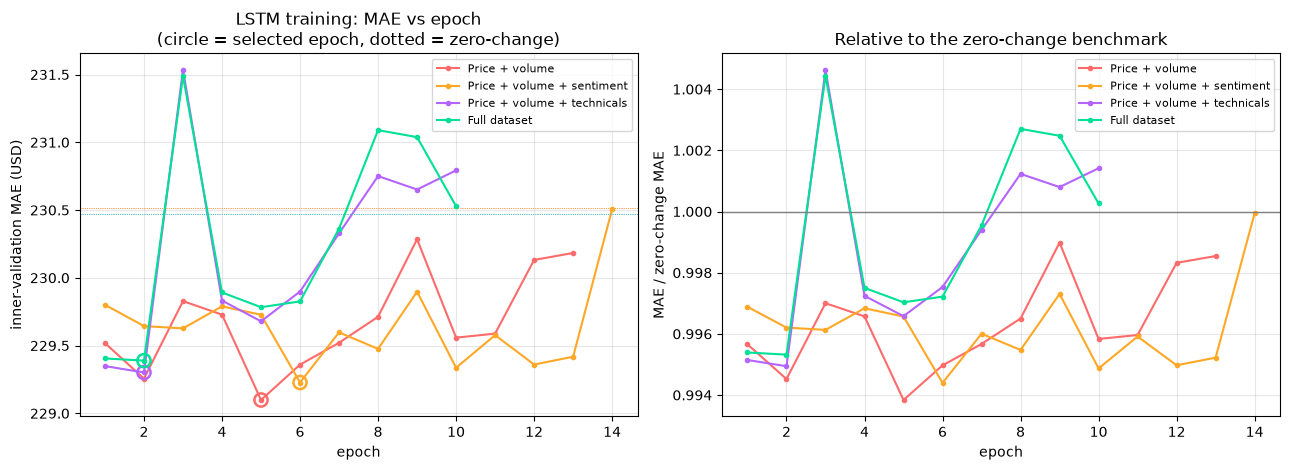

            feature_set  seed  selected_epoch  inner_val_MAE  zero_change_inner_MAE  ratio
           price+volume     0               5        229.098                230.519  0.994
           price+volume     1               2        229.254                230.519  0.995
           price+volume     2               3        229.303                230.519  0.995
 price+volume+sentiment     0               6        229.228                230.519  0.994
 price+volume+sentiment     1               4        229.350                230.519  0.995
 price+volume+sentiment     2               5        229.422                230.519  0.995
price+volume+technicals     0               2        229.302                230.467  0.995
price+volume+technicals     1               3        229.154                230.467  0.994
price+volume+technicals     2               2        229.388                230.467  0.995
                   full     0               2        229.389                230.467  0.995

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
colors = dict(zip(L.FEATURE_SET_ORDER,
                  ["#FF6B6B", "#FFA726", "#B565FF", "#00E096"]))

zero_change_inner = {}
for name in L.FEATURE_SET_ORDER:
    dfh = HOURLY_C[name]
    _, y_all, idx_all, _, _ = L.make_windows(dfh)
    zero_change_inner[name] = float(np.abs(y_all[inner_mask(idx_all)]).mean())

for name in L.FEATURE_SET_ORDER:
    hist = np.array(sel_runs[(name, SEEDS[0])]["history"])
    ep = np.arange(1, len(hist) + 1)
    best = sel_runs[(name, SEEDS[0])]["best_epoch"] + 1
    ax[0].plot(ep, hist, marker="o", ms=3, color=colors[name], label=L.NICE_NAME[name])
    ax[0].scatter([best], [hist[best - 1]], s=90, facecolors="none",
                  edgecolors=colors[name], linewidths=1.8, zorder=5)
    ax[0].axhline(zero_change_inner[name], lw=0.6, ls=":", color=colors[name])
    ax[1].plot(ep, hist / zero_change_inner[name], marker="o", ms=3,
               color=colors[name], label=L.NICE_NAME[name])

ax[0].set_ylabel("inner-validation MAE (USD)")
ax[0].set_title("LSTM training: MAE vs epoch\n(circle = selected epoch, dotted = zero-change)")
ax[1].axhline(1.0, lw=1.0, color="grey")
ax[1].set_ylabel("MAE / zero-change MAE")
ax[1].set_title("Relative to the zero-change benchmark")
for a in ax:
    a.set_xlabel("epoch")
    a.legend(fontsize=8)
    a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(L.OUT / "epochs_lstm.png", dpi=150)
plt.show()

epoch_tbl = pd.DataFrame([
    dict(feature_set=n, seed=s,
         selected_epoch=sel_runs[(n, s)]["best_epoch"] + 1,
         inner_val_MAE=sel_runs[(n, s)]["best_mae"],
         zero_change_inner_MAE=zero_change_inner[n],
         ratio=sel_runs[(n, s)]["best_mae"] / zero_change_inner[n])
    for n in L.FEATURE_SET_ORDER for s in SEEDS])
RESULTS["epoch_selection"] = epoch_tbl
print(epoch_tbl.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

## 5. Out-of-sample forecasting performance

Per feature set and regime, averaged over the three seeds. Metric definitions
are identical to the iTransformer table: MAE and RMSE in USD, MAE expressed as
a percentage of the price at the forecast origin, the Pearson correlation
between predicted and realised next-hour changes, and directional accuracy.

In [6]:
corrected_rows = []
for name in L.FEATURE_SET_ORDER:
    for regime in ("Uptrend", "Sideways"):
        per_seed = []
        for seed in SEEDS:
            run = runs[(name, seed)]
            m = L.regime_mask(run["idx"], regime, SIDEWAYS_END)
            per_seed.append(L.metrics(run["pred"][m], run["y"][m],
                                      run["close_prev"][m], name, regime))
        agg = {k: float(np.mean([d[k] for d in per_seed]))
               for k in ("MAE_usd", "RMSE_usd", "MAE_pct", "corr", "dir_acc",
                         "mean_pred", "std_pred")}
        agg |= {f"{k}_sd": float(np.std([d[k] for d in per_seed]))
                for k in ("MAE_usd", "RMSE_usd", "MAE_pct", "corr", "dir_acc")}
        corrected_rows.append(dict(regime=regime, model=name, n=per_seed[0]["n"],
                                   seeds=len(SEEDS), **agg))

corrected = pd.DataFrame(corrected_rows)
RESULTS["forecasting_performance"] = corrected
print(corrected[["regime", "model", "n", "MAE_usd", "MAE_usd_sd", "RMSE_usd",
                 "RMSE_usd_sd", "MAE_pct", "corr", "corr_sd", "dir_acc",
                 "dir_acc_sd"]].to_string(index=False,
                                          float_format=lambda v: f"{v:.4f}"))

  regime                   model    n  MAE_usd  MAE_usd_sd  RMSE_usd  RMSE_usd_sd  MAE_pct   corr  corr_sd  dir_acc  dir_acc_sd
 Uptrend            price+volume 5136 255.3002      0.1515  396.2172       0.1251   0.3557 0.0569   0.0026  52.6907      0.3117
Sideways            price+volume 2150 358.1138      0.4892  558.4507       0.3610   0.3850 0.0266   0.0026  51.5814      0.1973
 Uptrend  price+volume+sentiment 5136 255.3645      0.1922  396.2572       0.0489   0.3558 0.0571   0.0018  52.3272      0.2827
Sideways  price+volume+sentiment 2150 358.2624      0.3993  558.5343       0.1200   0.3852 0.0290   0.0042  51.4419      0.1005
 Uptrend price+volume+technicals 5120 255.6882      0.2857  396.6702       0.0427   0.3562 0.0499   0.0002  52.9986      0.5709
Sideways price+volume+technicals 2147 357.9276      0.6235  558.6343       0.1170   0.3848 0.0224   0.0028  51.5603      0.2742
 Uptrend                    full 5120 255.7708      0.2280  396.7294       0.0501   0.3563 0.0477   0.00

## 6. Naive benchmarks

Computed on the same evaluation windows, from the `full` frame, which is the
most restrictive of the four.

In [7]:
ref = HOURLY_C["full"]
_, y_ref, idx_ref, cp_ref, _ = L.make_windows(ref)

baseline_rows = []
for regime in ("Uptrend", "Sideways"):
    m = L.regime_mask(idx_ref, regime, SIDEWAYS_END)
    y, cp = y_ref[m], cp_ref[m]
    hist_mean = float(y_ref[train_mask(idx_ref)].mean())

    baseline_rows.append(L.metrics(np.zeros_like(y), y, cp, "zero change", regime))
    baseline_rows.append(L.metrics(np.full_like(y, hist_mean), y, cp,
                                   "historical mean (train)", regime))
    prev = np.concatenate([[np.nan], y[:-1]])
    ok = np.isfinite(prev)
    baseline_rows.append(L.metrics(prev[ok], y[ok], cp[ok],
                                   "random walk (last change)", regime))
    for p in (1, 24):
        pr, ya, ev = L.ar_forecast(y_ref, idx_ref, train_mask,
                                   lambda i, rg=regime: L.regime_mask(i, rg, SIDEWAYS_END), p)
        baseline_rows.append(L.metrics(pr, ya, cp_ref[ev], f"AR({p}) (OLS on train)", regime))

baselines = pd.DataFrame(baseline_rows)
RESULTS["baselines"] = baselines
print(baselines[["regime", "model", "n", "MAE_usd", "RMSE_usd", "MAE_pct",
                 "corr", "dir_acc"]].to_string(index=False,
                                                float_format=lambda v: f"{v:.4f}"))

zc_map = {r.regime: r.MAE_usd for r in baselines.itertuples() if r.model == "zero change"}
print("\nMAE relative to the zero-change benchmark:")
for regime in ("Uptrend", "Sideways"):
    for name in L.FEATURE_SET_ORDER:
        r = corrected[(corrected.regime == regime) & (corrected.model == name)].iloc[0]
        print(f"  {regime:9s} {name:26s} {r.MAE_usd / zc_map[regime]:.3f}x")

  regime                     model    n  MAE_usd  RMSE_usd  MAE_pct    corr  dir_acc
 Uptrend               zero change 5120 256.7578  397.0329   0.3576     NaN      NaN
 Uptrend   historical mean (train) 5120 256.7355  397.0191   0.3576     NaN  51.1037
 Uptrend random walk (last change) 5119 383.8921  567.5278   0.5354 -0.0216  46.3944
 Uptrend      AR(1) (OLS on train) 5120 256.7155  397.0130   0.3575  0.0216  50.9865
 Uptrend     AR(24) (OLS on train) 5120 257.0565  397.1775   0.3580  0.0265  50.7521
Sideways               zero change 2147 358.1826  557.9443   0.3852     NaN      NaN
Sideways   historical mean (train) 2147 358.1761  557.9565   0.3851     NaN  50.3493
Sideways random walk (last change) 2146 523.2955  795.6354   0.5621 -0.0169  47.6701
Sideways      AR(1) (OLS on train) 2147 358.1563  557.9499   0.3851  0.0168  50.3959
Sideways     AR(24) (OLS on train) 2147 359.7177  560.5163   0.3868 -0.0403  50.9082

MAE relative to the zero-change benchmark:
  Uptrend   price+vol

## 7. Diebold–Mariano tests

On absolute errors of the seed-averaged forecast, against the zero-change
benchmark and between each sentiment-bearing feature set and its
sentiment-free counterpart. Newey–West long-run variance, Harvey–Leybourne–Newbold
small-sample correction, Benjamini–Hochberg across the family.

In [8]:
frames = {}
for name in L.FEATURE_SET_ORDER:
    preds = pd.DataFrame({s: pd.Series(runs[(name, s)]["pred"], index=runs[(name, s)]["idx"])
                          for s in SEEDS})
    y = pd.Series(runs[(name, SEEDS[0])]["y"], index=runs[(name, SEEDS[0])]["idx"])
    frames[name] = pd.DataFrame({"err": preds.mean(axis=1) - y, "y": y})

common_idx = None
for f in frames.values():
    common_idx = f.index if common_idx is None else common_idx.intersection(f.index)
print(f"common evaluation index across all four feature sets: {len(common_idx):,} hours")

err_df = pd.DataFrame({n: f.loc[common_idx, "err"] for n, f in frames.items()})
err_df["zero change"] = -frames["full"].loc[common_idx, "y"]

dm_rows = []
for regime in ("Uptrend", "Sideways"):
    m = L.regime_mask(err_df.index, regime, SIDEWAYS_END)
    sub = err_df[m]
    for name in L.FEATURE_SET_ORDER:
        r = L.dm_test(sub[name].to_numpy(), sub["zero change"].to_numpy(), loss="abs")
        dm_rows.append(dict(regime=regime, comparison=f"{name}  vs  zero change",
                            d_mean=r["dbar"], DM=r["dm"], p=r["p"], n=r["n"]))
    for a, b in [("price+volume+sentiment", "price+volume"),
                 ("full", "price+volume+technicals")]:
        r = L.dm_test(sub[a].to_numpy(), sub[b].to_numpy(), loss="abs")
        dm_rows.append(dict(regime=regime, comparison=f"{a}  vs  {b}",
                            d_mean=r["dbar"], DM=r["dm"], p=r["p"], n=r["n"]))

dm = pd.DataFrame(dm_rows)
dm["q_BH"] = L.bh_qvalues(dm["p"])
RESULTS["dm_tests"] = dm
print(dm.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nNegative DM => the first model has the LOWER absolute error.")
print("q_BH >= 0.05 => no detectable difference in predictive accuracy.")

common evaluation index across all four feature sets: 7,267 hours
  regime                               comparison  d_mean      DM      p    n   q_BH
 Uptrend            price+volume  vs  zero change -1.3305 -4.0914 0.0000 5120 0.0005
 Uptrend  price+volume+sentiment  vs  zero change -1.2593 -3.3586 0.0008 5120 0.0024
 Uptrend price+volume+technicals  vs  zero change -1.2008 -3.5517 0.0004 5120 0.0023
 Uptrend                    full  vs  zero change -1.0624 -3.3935 0.0007 5120 0.0024
 Uptrend price+volume+sentiment  vs  price+volume  0.0713  0.7494 0.4536 5120 0.5853
 Uptrend        full  vs  price+volume+technicals  0.1384  1.2142 0.2247 5120 0.4495
Sideways            price+volume  vs  zero change -0.6194 -0.7625 0.4459 2147 0.5853
Sideways  price+volume+sentiment  vs  zero change -0.2856 -0.3118 0.7553 2147 0.7553
Sideways price+volume+technicals  vs  zero change -0.3719 -0.4351 0.6636 2147 0.7239
Sideways                    full  vs  zero change -0.5341 -0.6941 0.4877 2147 0.5853

## 8. LaTeX tables

Drop-in counterparts of the iTransformer tables in the manuscript.

In [9]:
lines = [
    r"\begin{table}[H]", r"\footnotesize", r"\centering", r"\begin{threeparttable}",
    r"\caption{Out-of-sample LSTM forecasting performance across validation "
    r"regimes. All feature sets share one date window, one chronological split "
    r"(training to " + f"{L.TRAIN_END.date()}" + r", May 2024 buffer), "
    r"standardised inputs and target, and epoch selection on a held-out inner "
    r"validation slice. Values are mean $\pm$ standard deviation over "
    + f"{len(SEEDS)}" + r" seeds.}",
    r"\label{tab:lstm_forecasting_performance_results}",
    r"\renewcommand{\arraystretch}{1.1}", r"\setlength{\tabcolsep}{4pt}",
    r"\begin{tabular}{llrccccc}", r"\toprule",
    r"\textbf{Regime} & \textbf{Feature set} & \textbf{n} & \textbf{MAE (USD)} & "
    r"\textbf{RMSE (USD)} & \textbf{MAE (\%)} & \textbf{Corr.} & "
    r"\textbf{Dir. Acc. (\%)} \\", r"\midrule",
]
for i, regime in enumerate(("Uptrend", "Sideways")):
    if i:
        lines.append(r"\midrule")
    for name in L.FEATURE_SET_ORDER:
        r = corrected[(corrected.regime == regime) & (corrected.model == name)].iloc[0]
        lines.append(
            f"{regime} & {L.NICE_NAME[name]} & {int(r.n):,} & "
            f"${r.MAE_usd:,.1f} \\pm {r.MAE_usd_sd:.1f}$ & "
            f"${r.RMSE_usd:,.1f} \\pm {r.RMSE_usd_sd:.1f}$ & "
            f"{r.MAE_pct:.3f} & "
            f"${r['corr']:+.4f} \\pm {r.corr_sd:.4f}$ & "
            f"${r.dir_acc:.2f} \\pm {r.dir_acc_sd:.2f}$ \\\\")
    lines.append(rf"\addlinespace {regime} & \textit{{Zero-change benchmark}} & "
                 rf"-- & \textit{{{zc_map[regime]:,.1f}}} & -- & -- & -- & -- \\")

vs_zero = dm[dm.comparison.str.contains("zero change")]
n_sig = int((vs_zero.q_BH < 0.05).sum())
n_worse = int(((vs_zero.q_BH < 0.05) & (vs_zero.DM > 0)).sum())
note = (r"\item \textit{Note:} Values are mean $\pm$ standard deviation over "
        f"{len(SEEDS)}"
        r" seeds. The target is the next-hour change in the BTCUSDT close, "
        r"reported in USD and as a percentage of the price at the forecast "
        r"origin. Correlation denotes the Pearson correlation between predicted "
        r"and realized next-hour price changes; directional accuracy reports the "
        r"percentage of observations for which the predicted and realized signs "
        r"agree. Diebold--Mariano tests are reported in "
        r"Table~\ref{tab:lstm_dm_tests}: "
        f"{n_sig} of {len(vs_zero)} comparisons against the zero-change "
        f"benchmark are significant at $q<0.05$, {n_worse} of them with a "
        r"\emph{positive} statistic, i.e.\ the fitted model has the "
        r"\emph{higher} absolute error.")
lines += [r"\bottomrule", r"\end{tabular}", r"\begin{tablenotes}[flushleft]",
          r"\footnotesize", note, r"\end{tablenotes}", r"\end{threeparttable}",
          r"\end{table}"]
tex_forecast = "\n".join(lines)
(L.OUT / "table_lstm_forecasting.tex").write_text(tex_forecast)
print(tex_forecast)

\begin{table}[H]
\footnotesize
\centering
\begin{threeparttable}
\caption{Out-of-sample LSTM forecasting performance across validation regimes. All feature sets share one date window, one chronological split (training to 2024-04-30, May 2024 buffer), standardised inputs and target, and epoch selection on a held-out inner validation slice. Values are mean $\pm$ standard deviation over 3 seeds.}
\label{tab:lstm_forecasting_performance_results}
\renewcommand{\arraystretch}{1.1}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{llrccccc}
\toprule
\textbf{Regime} & \textbf{Feature set} & \textbf{n} & \textbf{MAE (USD)} & \textbf{RMSE (USD)} & \textbf{MAE (\%)} & \textbf{Corr.} & \textbf{Dir. Acc. (\%)} \\
\midrule
Uptrend & Price + volume & 5,136 & $255.3 \pm 0.2$ & $396.2 \pm 0.1$ & 0.356 & $+0.0569 \pm 0.0026$ & $52.69 \pm 0.31$ \\
Uptrend & Price + volume + sentiment & 5,136 & $255.4 \pm 0.2$ & $396.3 \pm 0.0$ & 0.356 & $+0.0571 \pm 0.0018$ & $52.33 \pm 0.28$ \\
Uptrend & Price + volume + tech

In [10]:
lines = [
    r"\begin{table}[H]", r"\footnotesize", r"\centering", r"\begin{threeparttable}",
    r"\caption{Diebold--Mariano tests of equal predictive accuracy for the LSTM "
    r"forecasts, on absolute errors of the seed-averaged forecast.}",
    r"\label{tab:lstm_dm_tests}",
    r"\renewcommand{\arraystretch}{1.1}", r"\setlength{\tabcolsep}{6pt}",
    r"\begin{tabular}{llrrrr}", r"\toprule",
    r"\textbf{Regime} & \textbf{Comparison} & \textbf{n} & $\bar{d}$ & "
    r"\textbf{DM} & $\bm{q_{BH}}$ \\", r"\midrule",
]
for i, regime in enumerate(("Uptrend", "Sideways")):
    if i:
        lines.append(r"\midrule")
    for r in dm[dm.regime == regime].itertuples():
        comp = r.comparison.replace("  vs  ", " vs.\\ ").replace("_", r"\_")
        for k, v in L.NICE_NAME.items():
            comp = comp.replace(k, v)
        lines.append(f"{regime} & {comp} & {int(r.n):,} & {r.d_mean:+.2f} & "
                     f"{r.DM:+.3f} & {r.q_BH:.4f} \\\\")
lines += [
    r"\bottomrule", r"\end{tabular}", r"\begin{tablenotes}[flushleft]",
    r"\footnotesize",
    r"\item \textit{Note:} $\bar{d}$ is the mean difference in absolute error "
    r"(first model minus second), in USD. A negative DM statistic indicates the "
    r"first model has the lower absolute error. The long-run variance uses a "
    r"Newey--West estimator with the Harvey--Leybourne--Newbold small-sample "
    r"correction; $q_{BH}$ is the Benjamini--Hochberg adjusted p-value across "
    r"the whole family of tests in this table.",
    r"\end{tablenotes}", r"\end{threeparttable}", r"\end{table}"]
tex_dm = "\n".join(lines)
(L.OUT / "table_lstm_dm.tex").write_text(tex_dm)
print(tex_dm)

\begin{table}[H]
\footnotesize
\centering
\begin{threeparttable}
\caption{Diebold--Mariano tests of equal predictive accuracy for the LSTM forecasts, on absolute errors of the seed-averaged forecast.}
\label{tab:lstm_dm_tests}
\renewcommand{\arraystretch}{1.1}
\setlength{\tabcolsep}{6pt}
\begin{tabular}{llrrrr}
\toprule
\textbf{Regime} & \textbf{Comparison} & \textbf{n} & $\bar{d}$ & \textbf{DM} & $\bm{q_{BH}}$ \\
\midrule
Uptrend & Price + volume vs.\ zero change & 5,120 & -1.33 & -4.091 & 0.0005 \\
Uptrend & Price + volume+sentiment vs.\ zero change & 5,120 & -1.26 & -3.359 & 0.0024 \\
Uptrend & Price + volume+technicals vs.\ zero change & 5,120 & -1.20 & -3.552 & 0.0023 \\
Uptrend & Full dataset vs.\ zero change & 5,120 & -1.06 & -3.394 & 0.0024 \\
Uptrend & Price + volume+sentiment vs.\ Price + volume & 5,120 & +0.07 & +0.749 & 0.5853 \\
Uptrend & Full dataset vs.\ Price + volume+technicals & 5,120 & +0.14 & +1.214 & 0.4495 \\
\midrule
Sideways & Price + volume vs.\ zero change & 2

In [11]:
lines = [
    r"\begin{table}[ht]", r"\footnotesize", r"\centering", r"\begin{threeparttable}",
    r"\caption{Final LSTM hyperparameters for the four forecasting feature sets.}",
    r"\label{tab:lstm_hparams}",
    r"\renewcommand{\arraystretch}{1.15}", r"\setlength{\tabcolsep}{6pt}",
    r"\begin{tabular}{lcccc}", r"\toprule",
    r"\textbf{Feature set} & \textbf{hidden} & \textbf{layers} & "
    r"\textbf{dropout} & \textbf{lr} \\", r"\midrule",
]
for name in L.FEATURE_SET_ORDER:
    hp = BEST_HP[name]
    lines.append(f"{L.NICE_NAME[name]} & {hp['hidden_size']} & {hp['num_layers']} & "
                 f"{hp['dropout']:.3f} & {hp['lr']:.6f} \\\\")
lines += [
    r"\bottomrule", r"\end{tabular}", r"\begin{tablenotes}[flushleft]",
    r"\footnotesize",
    r"\item \textit{Note:} Selected by an Optuna study per feature set (" +
    f"{N_TRIALS}" + r" trials with median pruning, each trial trained for "
    + f"{TUNE_EPOCHS}" + r" epochs on a reduced corpus of the first "
    + f"{TUNE_CORPUS:,}" + r" training sequences, "
    + f"{TUNE_CORPUS_SMALL:,}" + r" for the price-and-volume set), scored by "
    r"validation MAE on the inner-validation slice of the training period. The "
    r"encoder is a unidirectional stacked LSTM with a linear head on the final "
    r"hidden state. Batch size 256 and AdamW with the Huber loss on the "
    r"standardised target are common to all runs.",
    r"\end{tablenotes}", r"\end{threeparttable}", r"\end{table}"]
tex_hp = "\n".join(lines)
(L.OUT / "table_lstm_hparams.tex").write_text(tex_hp)
print(tex_hp)

\begin{table}[ht]
\footnotesize
\centering
\begin{threeparttable}
\caption{Final LSTM hyperparameters for the four forecasting feature sets.}
\label{tab:lstm_hparams}
\renewcommand{\arraystretch}{1.15}
\setlength{\tabcolsep}{6pt}
\begin{tabular}{lcccc}
\toprule
\textbf{Feature set} & \textbf{hidden} & \textbf{layers} & \textbf{dropout} & \textbf{lr} \\
\midrule
Price + volume & 32 & 1 & 0.224 & 0.002624 \\
Price + volume + sentiment & 64 & 1 & 0.103 & 0.002070 \\
Price + volume + technicals & 128 & 1 & 0.089 & 0.001318 \\
Full dataset & 128 & 1 & 0.003 & 0.000922 \\
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]
\footnotesize
\item \textit{Note:} Selected by an Optuna study per feature set (50 trials with median pruning, each trial trained for 5 epochs on a reduced corpus of the first 10,000 training sequences, 5,000 for the price-and-volume set), scored by validation MAE on the inner-validation slice of the training period. The encoder is a unidirectional stacked LSTM with a 

## 9. Persist everything

In [12]:
for key, obj in RESULTS.items():
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(L.OUT / f"{key}.csv", index=False)


def excel_safe(df):
    out = df.copy()
    for c in out.columns:
        if isinstance(out[c].dtype, pd.DatetimeTZDtype):
            out[c] = out[c].astype(str)
        elif out[c].dtype == object:
            out[c] = out[c].map(lambda v: str(v) if isinstance(v, pd.Timestamp) else v)
    return out


try:
    with pd.ExcelWriter(L.OUT / "lstm_forecasting_tables.xlsx") as xl:
        for key, obj in RESULTS.items():
            if isinstance(obj, pd.DataFrame):
                excel_safe(obj).to_excel(xl, sheet_name=key[:31], index=False)
except Exception as e:
    print(f"xlsx not written ({type(e).__name__}: {e}); CSVs are complete")

print("written to", L.OUT)
for p in sorted(L.OUT.iterdir()):
    print("  ", p.name)
print("\ncheckpoints:")
for p in sorted(L.CKPT_DIR.iterdir()):
    print("  ", p.name)

written to /home/kosmo/Documents/Magis-submit/src-vibe (Copy)/lstm_models/out
   baselines.csv
   data_split.csv
   dm_tests.csv
   epoch_selection.csv
   epochs_lstm.png
   forecasting_performance.csv
   lstm_forecasting_tables.xlsx
   lstm_hparams.csv
   lstm_hparams.json
   lstm_predictions.npz
   table_lstm_dm.tex
   table_lstm_forecasting.tex
   table_lstm_hparams.tex

checkpoints:
   lstm_full_dataset.pt
   lstm_price_only.pt
   lstm_sentiment_only.pt
   lstm_technicals_only.pt


## 10. Summary

In [13]:
print("=" * 78)
print("LSTM FORECASTING — SUMMARY")
print("=" * 78)
for regime in ("Uptrend", "Sideways"):
    print(f"\n{regime}  (zero-change MAE = {zc_map[regime]:.1f} USD)")
    for name in L.FEATURE_SET_ORDER:
        r = corrected[(corrected.regime == regime) & (corrected.model == name)].iloc[0]
        print(f"  {L.NICE_NAME[name]:28s} MAE {r.MAE_usd:7.1f} +/- {r.MAE_usd_sd:4.1f} "
              f"({r.MAE_usd / zc_map[regime]:.3f}x)   corr {r['corr']:+.4f} "
              f"+/- {r.corr_sd:.4f}   dir.acc {r.dir_acc:5.2f}%")
noise = {rg: 1 / np.sqrt(corrected[corrected.regime == rg].n.iloc[0])
         for rg in ("Uptrend", "Sideways")}
print(f"\nCorrelation sampling noise 1/sqrt(n): uptrend {noise['Uptrend']:.4f}, "
      f"sideways {noise['Sideways']:.4f}")
print("\nNext: run 02_lstm_backtesting.ipynb, then 03_lstm_diagrams.ipynb.")

LSTM FORECASTING — SUMMARY

Uptrend  (zero-change MAE = 256.8 USD)
  Price + volume               MAE   255.3 +/-  0.2 (0.994x)   corr +0.0569 +/- 0.0026   dir.acc 52.69%
  Price + volume + sentiment   MAE   255.4 +/-  0.2 (0.995x)   corr +0.0571 +/- 0.0018   dir.acc 52.33%
  Price + volume + technicals  MAE   255.7 +/-  0.3 (0.996x)   corr +0.0499 +/- 0.0002   dir.acc 53.00%
  Full dataset                 MAE   255.8 +/-  0.2 (0.996x)   corr +0.0477 +/- 0.0019   dir.acc 52.81%

Sideways  (zero-change MAE = 358.2 USD)
  Price + volume               MAE   358.1 +/-  0.5 (1.000x)   corr +0.0266 +/- 0.0026   dir.acc 51.58%
  Price + volume + sentiment   MAE   358.3 +/-  0.4 (1.000x)   corr +0.0290 +/- 0.0042   dir.acc 51.44%
  Price + volume + technicals  MAE   357.9 +/-  0.6 (0.999x)   corr +0.0224 +/- 0.0028   dir.acc 51.56%
  Full dataset                 MAE   357.8 +/-  0.5 (0.999x)   corr +0.0234 +/- 0.0007   dir.acc 51.50%

Correlation sampling noise 1/sqrt(n): uptrend 0.0140, sidew